# 3. Market vs. fundamentals (the edge signal)

We fit how the market prices a profile (projected points, age, experience, draft capital, position) using **out-of-fold** predictions. The residual says whether a player is priced above or below similar profiles. It is a relative-value signal, not a forecast that the market is wrong. Rookies without NFL history are excluded.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from datascience.features import *
from datascience.model import *
from datascience.collect import load_snapshots, load_trades
import json
edges = json.load(open('../dynasty/data/model_edges.json'))
print(edges['snapshot_date'], edges['data_season'], edges['metrics']['model'])
q2 = pd.DataFrame(edges['formats']['q2']['players']).T
q2['z'] = q2.z.astype(float)
print(edges['formats']['q2']['diagnostics'])
q2.sort_values('z', ascending=False).head(10)[['name','position','market_value','fundamental_value','edge','z','pred_points']]

2026-10-15 2025 {'band_coverage': 0.774, 'folds': 7, 'mae': 42.22, 'rmse': 59.5, 'spearman': 0.708}
{'bench_cap': 76, 'n_fit': 226, 'oof_r2_log_value': 0.527, 'residual_sigma_log': 0.58}


,name,position,market_value,fundamental_value,edge,z,pred_points
12498,Mason Taylor,TE,350,1952,1602,2.96,108.9
11627,Troy Franklin,WR,384,1813,1429,2.68,150.0
8172,Greg Dulcich,TE,340,1509,1169,2.57,51.5
9229,Anthony Richardson,QB,611,2312,1701,2.30,103.7
7049,Jauan Jennings,WR,451,1605,1154,2.19,120.4
11565,J.J. McCarthy,QB,947,3078,2131,2.03,140.0
12499,Elic Ayomanor,WR,450,1463,1013,2.03,122.9
6768,Tua Tagovailoa,QB,517,1611,1094,1.96,146.3
10218,Xavier Hutchinson,WR,311,964,653,1.95,68.4
2307,Marcus Mariota,QB,478,1449,971,1.91,85.9


In [2]:
q2.sort_values('z').head(10)[['name','position','market_value','fundamental_value','edge','z','pred_points']]

,name,position,market_value,fundamental_value,edge,z,pred_points
8131,Isaiah Likely,TE,2721,569,-2152,-2.70,55.1
9487,Parker Washington,WR,4130,994,-3136,-2.46,145.8
8151,Kenneth Walker,RB,6980,1861,-5119,-2.28,157.8
11632,Malik Nabers,WR,5969,1725,-4244,-2.14,134.5
12501,Matthew Golden,WR,3283,975,-2308,-2.09,89.4
11604,Brock Bowers,TE,8127,2453,-5674,-2.07,183.6
12490,Bhayshul Tuten,RB,3138,949,-2189,-2.06,85.9
12519,Luther Burden,WR,3094,954,-2140,-2.03,129.6
8167,Christian Watson,WR,3946,1256,-2690,-1.98,110.8
2216,Mike Evans,WR,2242,809,-1433,-1.76,70.4


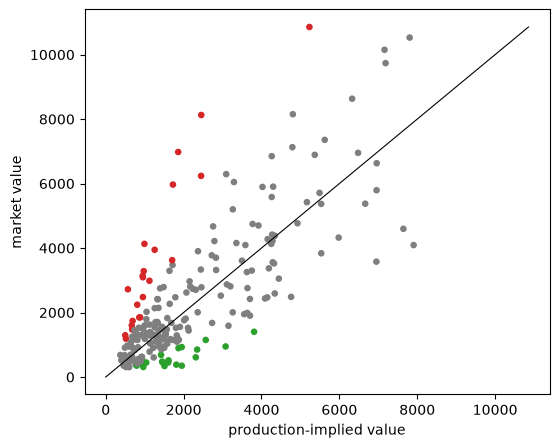

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
colors = q2.signal.map({'buy':'tab:green','sell':'tab:red','hold':'tab:grey'})
ax.scatter(q2.fundamental_value.astype(float), q2.market_value.astype(float), c=colors, s=14)
m = max(q2.fundamental_value.astype(float).max(), q2.market_value.astype(float).max())
ax.plot([0, m], [0, m], 'k-', lw=0.8); ax.set_xlabel('production-implied value'); ax.set_ylabel('market value'); plt.show()

## Caveats
The value model explains roughly half the variance of log market value, so edges are noisy. Injured players (a lost season looks like low production) and players whose role changed show up as 'sell' even if the market is right. Use the signal as a prompt to look closer.